# 多分类神经网络在量子关联分类中的应用研究

Research on the application of multi-classification neural network in quantum correlation classification (MCNN-QCC)

## 概要

本课题将通过知名深度学习框架Pytorch搭建神经网络，分析QCC数据集，观察训练误差和验证误差随训练代数提高的变化。

徐浩轩 集美大学 2023-12

GitHub：[ollyhsu/MCNN-QCC](https://github.com/ollyhsu/MCNN-QCC)


# 环境准备

## 下载Pytorch

打开浏览器，访问 [PyTorch官方网站](https://pytorch.org/)

在官网首页，你会看到一个“Get Started”（开始使用）的按钮或类似的链接，点击它

接下来，你可能需要选择一些选项，比如选择你的操作系统、安装方式（例如pip或conda）、Python版本等。根据你的需求进行选择，并点击相关选项

完成上述步骤后，网站会为你生成一个相应的安装命令。复制这个命令，它会类似于：

```bash
pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```

## 验证环境

你可以运行以下代码单元来验证PyTorch的安装是否成功，并检查CUDA是否可用以及CUDA的版本：

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
# from tqdm import tqdm

%matplotlib inline
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
label_dic = {0: 'fully-separable states', 1: 'two-separable states', 2: 'entangled states'}

In [2]:
# -*- coding: utf-8 -*-
import seaborn as sns
from matplotlib import pyplot as plt
import warnings
# Disable specific warning
warnings.filterwarnings("ignore", category=UserWarning, message=".*cudnnException.*")

# 功能函数
# model trainer
def model_trainer(num_epochs, train_dataloader, test_dataloader, model, criterion, optimizer):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.train()

    # 将每次训练的训练误差和测试误差存储在这两个列表里，后面绘制误差变化折线图用
    train_losses, test_losses, train_accs, test_accs = [], [], [], []

    print('Start training')
    print('Epoch\tTrain Loss\tTest Loss\tTest Accuracy/%')
    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # for inputs, labels in tqdm(train_dataloader, desc=f'Epoch {epoch + 1}/{num_epochs}', leave=False):
        for inputs, labels in train_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total_train += labels.size(0)
            correct_train += predicted.eq(labels).sum().item()

        # 每次学完一遍数据集，都进行以下测试操作
        model.eval()
        test_loss = 0.0
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            # for inputs, labels in tqdm(test_dataloader, desc='Test', leave=False):
            for inputs, labels in test_dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                test_loss += loss.item() * inputs.size(0)
                _, predicted = outputs.max(1)
                total_test += labels.size(0)
                correct_test += predicted.eq(labels).sum().item()

        train_loss = running_loss / len(train_dataloader.dataset)
        train_acc = 100. * correct_train / total_train
        test_loss = test_loss / len(test_dataloader.dataset)
        test_acc = 100. * correct_test / total_test

        # 恢复Dropout
        model.train()

        # 将训练误差和测试误差存在两个列表里，后面绘制误差变化折线图用
        train_losses.append(train_loss)
        test_losses.append(test_loss)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        print("{}\t".format(epoch + 1),
              "{:.4f}\t".format(train_loss),
              "{:.4f}\t".format(test_loss),
              "{:.3f}".format(test_acc))

    print('Finished Training')

    return train_losses, test_losses, train_accs, test_accs


def model_tester(test_dataloader, model):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # 初始化混淆矩阵和类别分类列表
    label_dic = {0: 'fully-separable states', 1: 'two-separable states', 2: 'entangled states'}
    num_classes = len(label_dic)
    conf_matrix = np.zeros((num_classes, num_classes))
    class_correct = list(0. for i in range(num_classes))
    class_total = list(0. for i in range(num_classes))

    # 将模型设置为评估模式
    model.eval()

    # 在测试集上进行测试
    with torch.no_grad():
        for inputs, labels in test_dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            c = (predicted == labels).squeeze()

            for i in range(len(labels)):
                label = labels[i]
                prediction = predicted[i]
                conf_matrix[label][prediction] += 1
                class_correct[label] += c[i].item()
                class_total[label] += 1

    # 计算混淆矩阵的百分比
    conf_matrix_percent = conf_matrix / np.sum(conf_matrix, axis=1, keepdims=True)

    # 计算每个类别的准确率
    class_accuracy = [100 * class_correct[i] / class_total[i] if class_total[i] > 0 else 0 for i in
                      range(num_classes)]

    # 计算精确率、召回率和 F1 值
    precision = [conf_matrix[i][i] / np.sum(conf_matrix[:, i]) if np.sum(conf_matrix[:, i]) > 0 else 0 for i in
                 range(num_classes)]
    recall = [conf_matrix[i][i] / np.sum(conf_matrix[i, :]) if np.sum(conf_matrix[i, :]) > 0 else 0 for i in
              range(num_classes)]
    f1 = [2 * precision[i] * recall[i] / (precision[i] + recall[i]) if precision[i] + recall[i] > 0 else 0 for i in
          range(num_classes)]

    return conf_matrix_percent, class_accuracy, precision, recall, f1


# Training and Test Loss
def draw_loss(train_losses, test_losses):
    # 训练次数
    epochs = range(1, len(train_losses) + 1)

    # 绘制训练误差和测试误差随学习次数增加的变化曲线
    plt.figure(figsize=(5, 4))
    plt.plot(epochs, train_losses, label='Train Loss', color='blue', marker='o')
    plt.plot(epochs, test_losses, label='Test Loss', color='orange', marker='s')

    # 添加标签和标题
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Test Loss')
    plt.legend()
    plt.grid(True)

    # 设置 x 轴刻度为每个 epoch 单位
    # plt.xticks(range(1, len(fc_train_losses) + 1))
    plt.xticks(range(0, len(epochs) + 1, 2))

    plt.show()


# Accuracy Curve
def draw_acc(train_accs, test_accs):
    # 训练次数
    epochs = range(1, len(train_accs) + 1)
    plt.figure(figsize=(5, 4))
    # 绘制准确率曲线图
    plt.plot(epochs, train_accs, label='Train Accuracy', color='blue')
    plt.plot(epochs, test_accs, label='Test Accuracy', color='orange')

    # 添加标签和标题
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Curve')
    plt.legend()
    plt.grid(True)

    plt.xticks(range(0, len(epochs) + 1, 2))

    # 显示图像
    plt.show()


# Confusion Matrix
def draw_confusion(conf_matrix_percent, label_dic):
    # 绘制混淆矩阵
    plt.figure(figsize=(5, 4))
    sns.heatmap(conf_matrix_percent, annot=False, cmap='Purples', fmt=".2f", xticklabels=label_dic.values(),
                yticklabels=label_dic.values())
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    # 设置 x 轴文字旋转角度为 30 度
    plt.xticks(rotation=30)

    plt.show()


# Classification accuracy
def draw_class_acc(class_accuracy, label_dic):
    plt.figure(figsize=(5, 4))
    bars = plt.bar(label_dic.values(), class_accuracy, color='skyblue')

    # 在每个条形上方添加文本标签
    for i, acc in enumerate(class_accuracy):
        plt.text(i, acc + 1, f'{acc:.2f}%', ha='center', va='bottom')

    plt.xlabel('Class')
    plt.ylabel('Accuracy (%)')
    plt.title('Classification accuracy', pad=20)
    plt.xticks(rotation=30)
    plt.ylim(0, 100)

    plt.show()


# Precision, Recall and F1 Score for each Class
def draw_prf1(precision, recall, f1, label_dic):
    # 绘制精确率、召回率和 F1 值的条形图
    x = np.arange(len(label_dic))
    width = 0.2
    # label_dic = {0: 'fully-separable states', 1: 'two-separable states', 2: 'entangled states'}
    fig, ax = plt.subplots(figsize=(10, 6))
    bars_precision = ax.bar(x - width, precision, width, label='Precision')
    bars_recall = ax.bar(x, recall, width, label='Recall')
    bars_f1 = ax.bar(x + width, f1, width, label='F1 Score')

    ax.set_xlabel('Class')
    ax.set_ylabel('Value')
    ax.set_title('Precision, Recall and F1 Score for each Class')
    ax.set_xticks(x)
    ax.set_xticklabels(label_dic.values(), rotation=30)

    # 添加数值标签
    def autolabel(bars):
        for bar in bars:
            height = bar.get_height()
            ax.annotate('%.2f' % height,
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom')

    autolabel(bars_precision)
    autolabel(bars_recall)
    autolabel(bars_f1)
    # 移动图例到右边
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

    plt.show()

In [3]:
# 检查CUDA是否可用
cuda_available = torch.cuda.is_available()
print("CUDA Available: ", cuda_available)

if cuda_available:
    # 打印CUDA设备数量
    device_count = torch.cuda.device_count()
    print("CUDA Device Count: ", device_count)

    # 打印CUDA版本
    cuda_version = torch.version.cuda
    print("CUDA Version: ", cuda_version)

CUDA Available:  True
CUDA Device Count:  1
CUDA Version:  12.1


运行此代码单元后，如果你看到输出显示CUDA可用、设备数量以及CUDA版本，则说明PyTorch已经成功安装，并且CUDA也可用

# 数据集准备

## 生成数据集

运行`genDataset.py` 文件，生成数据集至 `dataset` 目录下

数据集标签说明：

`0` for fully-separable states, `1` for two-separable states, `2` for entangled states

## 导入数据集

In [4]:
# 准备数据
train_mixes = np.load('dataset/qcc_train_set_mixes.npy')
train_labels = np.load('dataset/qcc_train_set_labels.npy')
test_mixes = np.load('dataset/qcc_test_set_mixes.npy')
test_labels = np.load('dataset/qcc_test_set_labels.npy')

# 将数据转换为 PyTorch 张量
train_mixes_tensor = torch.tensor(train_mixes, dtype=torch.float32)  # 转换训练集混合状态为张量
train_labels_tensor = torch.tensor(train_labels, dtype=torch.long)  # 转换训练集标签为张量

test_mixes_tensor = torch.tensor(test_mixes, dtype=torch.float32)  # 转换测试集混合状态为张量
test_labels_tensor = torch.tensor(test_labels, dtype=torch.long)  # 转换测试集标签为张量

# 提取实部和虚部
train_mixes_real = train_mixes_tensor[:, :, :, 0]  # 提取训练集混合状态的实部
train_mixes_imag = train_mixes_tensor[:, :, :, 1]  # 提取训练集混合状态的虚部

test_mixes_real = test_mixes_tensor[:, :, :, 0]  # 提取测试集混合状态的实部
test_mixes_imag = test_mixes_tensor[:, :, :, 1]  # 提取测试集混合状态的虚部

# 生成复数张量
train_mixes_complex = torch.stack((train_mixes_real, train_mixes_imag), dim=1)  # 组合实部和虚部生成复数张量
test_mixes_complex = torch.stack((test_mixes_real, test_mixes_imag), dim=1)  # 组合实部和虚部生成复数张量

# 创建 PyTorch 数据集
train_dataset = TensorDataset(train_mixes_complex, train_labels_tensor)  # 创建训练集
test_dataset = TensorDataset(test_mixes_complex, test_labels_tensor)  # 创建测试集

train_dataloader = DataLoader(train_dataset, batch_size=100, shuffle=True)  # 创建训练集数据加载器
test_dataloader = DataLoader(test_dataset, batch_size=100, shuffle=True)  # 创建测试集数据加载器


# print("Train Mixes Tensor Shape: ", train_mixes_tensor.shape)
# print("Train Labels Tensor Shape: ", train_labels_tensor.shape)
# print("Test Mixes Tensor Shape: ", test_mixes_tensor.shape)
# print("Test Labels Tensor Shape: ", test_labels_tensor.shape)

# 打印数据集和数据加载器的大小
print("Train Mixes Complex Shape: ", train_mixes_complex.shape)  # 打印训练集复数张量的形状
print("Test Mixes Complex Shape: ", test_mixes_complex.shape)  # 打印测试集复数张量的形状

print("Train Dataset Size: ", len(train_dataset))  # 打印训练集大小
print("Test Dataset Size: ", len(test_dataset))  # 打印测试集大小
print("Train Dataloader Size: ", len(train_dataloader))  # 打印训练集数据加载器大小
print("Test Dataloader Size: ", len(test_dataloader))  # 打印测试集数据加载器大小

Train Mixes ComplexShape:  torch.Size([24000, 2, 8, 8])
Test Mixes ComplexShape:  torch.Size([6000, 2, 8, 8])
Train Dataset Size:  24000
Test Dataset Size:  6000
Train Dataloader Size:  240
Test Dataloader Size:  60


# 多层感知机模型

## 多层感知机

神经网络的输入为 2 * 8 * 8 = 128 的张量

第一个隐含层包含256个神经元

第二个隐含层包含多128个神经元

第三个隐含层包含64个神经元

输出层输出3个结果，对应数据集量子态的3种分类

In [5]:
# 定义四层多层感知机模型
class MLPModel(nn.Module):
    def __init__(self):
        super(MLPModel, self).__init__()
        self.fc1 = nn.Linear(128, 256)  # 第一个隐藏层，输入大小为128，输出大小为256
        self.fc2 = nn.Linear(256, 128)  # 第二个隐藏层，输入大小为256，输出大小为128
        self.fc3 = nn.Linear(128, 64)  # 第三个隐藏层，输入大小为128，输出大小为64
        self.fc4 = nn.Linear(64, 3)  # 输出层，输入大小为64，输出大小为3（类别数量）

    def forward(self, x):
        x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = F.relu(self.fc1(x))  # 第一个隐藏层的激活函数为ReLU
        x = F.relu(self.fc2(x))  # 第二个隐藏层的激活函数为ReLU
        x = F.relu(self.fc3(x))  # 第三个隐藏层的激活函数为ReLU
        x = self.fc4(x)  # 输出层不需要激活函数，因为后面会使用交叉熵损失函数
        return x

In [6]:
# 实例化模型
model_mlp = MLPModel()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()  # 交叉熵损失函数
optimizer = optim.Adam(model_mlp.parameters(), lr=0.001)  # Adam 优化器

# 训练模型
num_epochs = 20

mlp_train_losses, mlp_test_losses, mlp_train_accs, mlp_test_accs = model_trainer(num_epochs, train_dataloader, test_dataloader, model_mlp, criterion, optimizer)

Start training
Epoch	Train Loss	Test Loss	Test Accuracy/%
1	 0.3675	 0.0755	 97.367
2	 0.0449	 0.0222	 99.500
3	 0.0228	 0.0487	 98.300
4	 0.0150	 0.0096	 99.717
5	 0.0112	 0.0166	 99.483
6	 0.0128	 0.0161	 99.583
7	 0.0079	 0.0052	 99.833
8	 0.0046	 0.0359	 98.717
9	 0.0139	 0.0533	 98.150
10	 0.0099	 0.0048	 99.900
11	 0.0029	 0.0074	 99.783
12	 0.0040	 0.0152	 99.467
13	 0.0019	 0.0049	 99.850
14	 0.0026	 0.0033	 99.883
15	 0.0072	 0.0035	 99.867
16	 0.0011	 0.0054	 99.833
17	 0.0023	 0.0065	 99.833
18	 0.0141	 0.0047	 99.817
19	 0.0021	 0.0036	 99.867
20	 0.0023	 0.0033	 99.933
Finished Training


In [7]:
# 保存模型
# torch.save(model_mlp.state_dict(), 'models/model_mlp.pth', _use_new_zipfile_serialization=False)

验证模型效果

绘制训练误差和测试误差随学习次数增加的变化

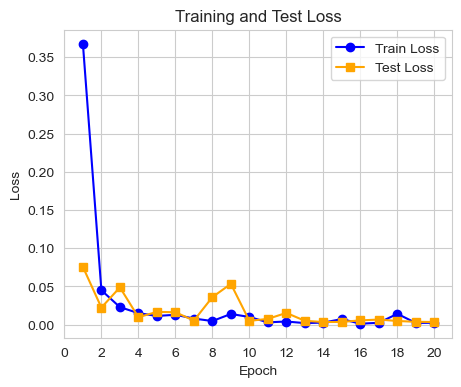

In [8]:
# Training and Test Loss
draw_loss(mlp_train_losses, mlp_test_losses)

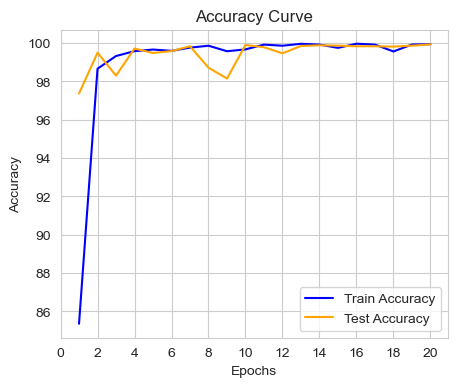

In [9]:
# Accuracy Curve
draw_acc(mlp_train_accs, mlp_test_accs)

In [10]:
# # 加载模型
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model_mlp = MLPModel()
# model_mlp.load_state_dict(torch.load('models/model_mlp.pth', map_location=device))
# model_mlp.to(device)

In [11]:
conf_matrix_percent_mlp, class_accuracy_mlp, precision_mlp, recall_mlp, f1_mlp = model_tester(test_dataloader, model_mlp)

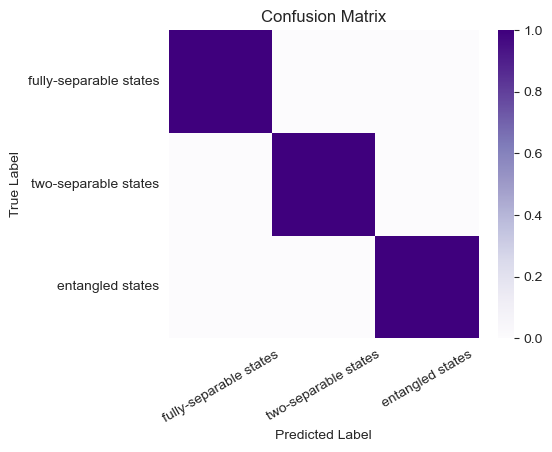

In [12]:
# Confusion Matrix
draw_confusion(conf_matrix_percent_mlp, label_dic)

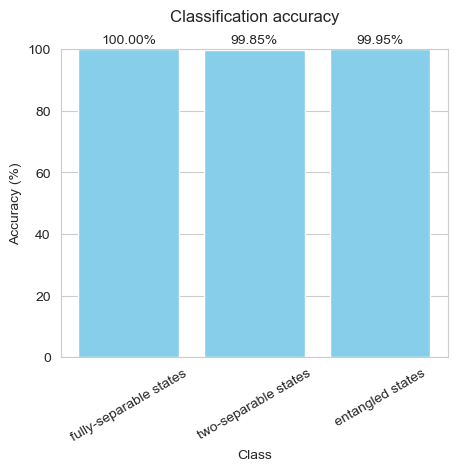

In [13]:
# Classification accuracy
draw_class_acc(class_accuracy_mlp, label_dic)

In [14]:
# 数据
precision = precision_mlp
recall = recall_mlp
f1 = f1_mlp
class_accuracy = class_accuracy_mlp

# 输出表头
print("Type\tPrecision/%\tRecall/%\tAccuracy/%\tF1")

# 输出每个类别的指标
for i, label in enumerate(label_dic.values()):
    print(f"{label}\t{precision[i] * 100:.2f}\t{recall[i] * 100:.2f}\t{class_accuracy[i]:.2f}\t{f1[i]:.2f}")

Type	Precision/%	Recall/%	Accuracy/%	F1
fully-separable states	99.85	100.00	100.00	1.00
two-separable states	99.95	99.85	99.85	1.00
entangled states	100.00	99.95	99.95	1.00


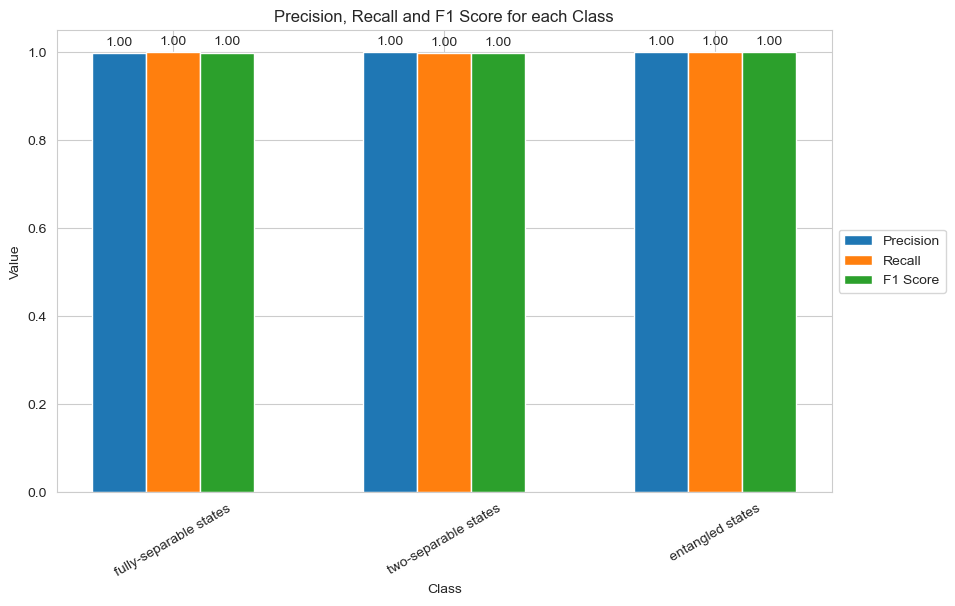

In [15]:
# Precision, Recall and F1 Score for each Class
draw_prf1(precision_mlp, recall_mlp, f1_mlp, label_dic)

## 采用Dropout防止过拟合

In [16]:
class MLPModelWithDropout(nn.Module):
    def __init__(self):
        super(MLPModelWithDropout, self).__init__()
        self.fc1 = nn.Linear(8 * 8 * 2, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 3)
        self.dropout = nn.Dropout(p=0.5)  # 添加 Dropout 层，p 参数表示丢弃概率

    def forward(self, x):
        x = x.view(-1, 8 * 8 * 2)  # 展平输入数据
        x = F.relu(self.fc1(x))
        x = self.dropout(x)  # 在第一个全连接层后添加 Dropout
        x = F.relu(self.fc2(x))
        x = self.dropout(x)  # 在第二个全连接层后添加 Dropout
        x = F.relu(self.fc3(x))
        x = self.dropout(x)  # 在第三个全连接层后添加 Dropout
        x = self.fc4(x)
        return x

In [17]:
# 实例化模型
model_mlpd = MLPModelWithDropout()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mlpd.parameters(), lr=0.001)

# 训练模型
num_epochs = 20

mlpd_train_losses, mlpd_test_losses, mlpd_train_accs, mlpd_test_accs = model_trainer(num_epochs, train_dataloader, test_dataloader, model_mlpd, criterion, optimizer)

Start training
Epoch	Train Loss	Test Loss	Test Accuracy/%
1	 0.5437	 0.1235	 95.867
2	 0.1352	 0.0463	 98.267
3	 0.0746	 0.0207	 99.433
4	 0.0542	 0.0227	 99.267
5	 0.0452	 0.0101	 99.783
6	 0.0356	 0.0137	 99.633
7	 0.0322	 0.0096	 99.733
8	 0.0270	 0.0096	 99.767
9	 0.0301	 0.0063	 99.833
10	 0.0302	 0.0048	 99.883
11	 0.0244	 0.0111	 99.700
12	 0.0225	 0.0084	 99.783
13	 0.0226	 0.0078	 99.717
14	 0.0207	 0.0054	 99.817
15	 0.0183	 0.0060	 99.867
16	 0.0229	 0.0064	 99.800
17	 0.0210	 0.0033	 99.917
18	 0.0169	 0.0035	 99.883
19	 0.0179	 0.0049	 99.817
20	 0.0183	 0.0099	 99.733
Finished Training


In [18]:
# 保存模型
# torch.save(model_mlpd.state_dict(), 'models/model_mlpd.pth', _use_new_zipfile_serialization=False)

验证模型效果

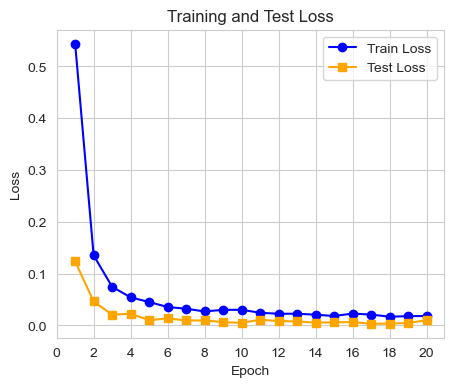

In [19]:
# Training and Test Loss
draw_loss(mlpd_train_losses, mlpd_test_losses)

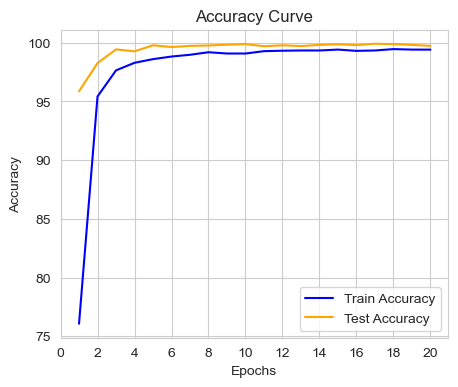

In [20]:
# Accuracy Curve
draw_acc(mlpd_train_accs, mlpd_test_accs)

In [21]:
# # 加载模型
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model_mlpd = MLPModelWithDropout()
# model_mlpd.load_state_dict(torch.load('models/model_mlpd.pth', map_location=device))
# model_mlpd.to(device)

In [22]:
conf_matrix_percent_mlpd, class_accuracy_mlpd, precision_mlpd, recall_mlpd, f1_mlpd = model_tester(test_dataloader, model_mlpd)

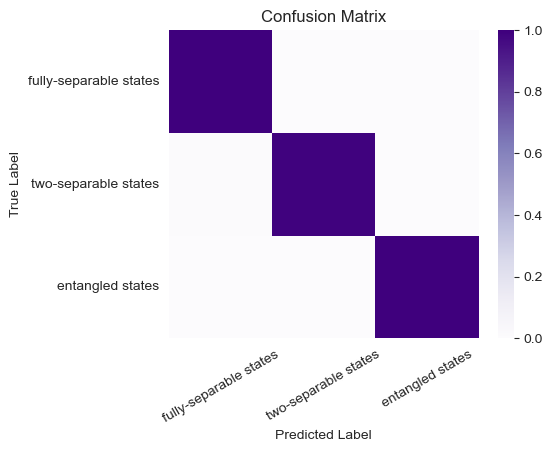

In [23]:
# Confusion Matrix
draw_confusion(conf_matrix_percent_mlpd, label_dic)

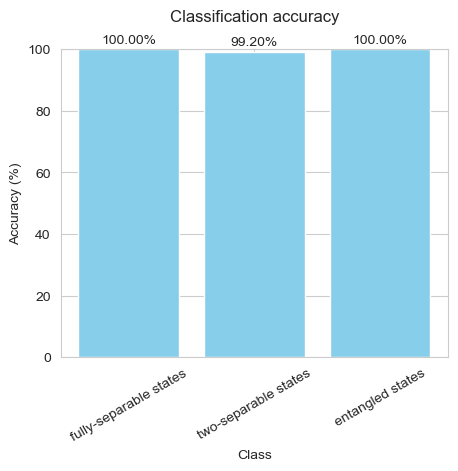

In [24]:
# Classification accuracy
draw_class_acc(class_accuracy_mlpd, label_dic)

In [25]:
# 数据
precision = precision_mlpd
recall = recall_mlpd
f1 = f1_mlpd
class_accuracy = class_accuracy_mlpd

# 输出表头
print("Type\tPrecision/%\tRecall/%\tAccuracy/%\tF1")

# 输出每个类别的指标
for i, label in enumerate(label_dic.values()):
    print(f"{label}\t{precision[i] * 100:.2f}\t{recall[i] * 100:.2f}\t{class_accuracy[i]:.2f}\t{f1[i]:.2f}")

Type	Precision/%	Recall/%	Accuracy/%	F1
fully-separable states	99.21	100.00	100.00	1.00
two-separable states	100.00	99.20	99.20	1.00
entangled states	100.00	100.00	100.00	1.00


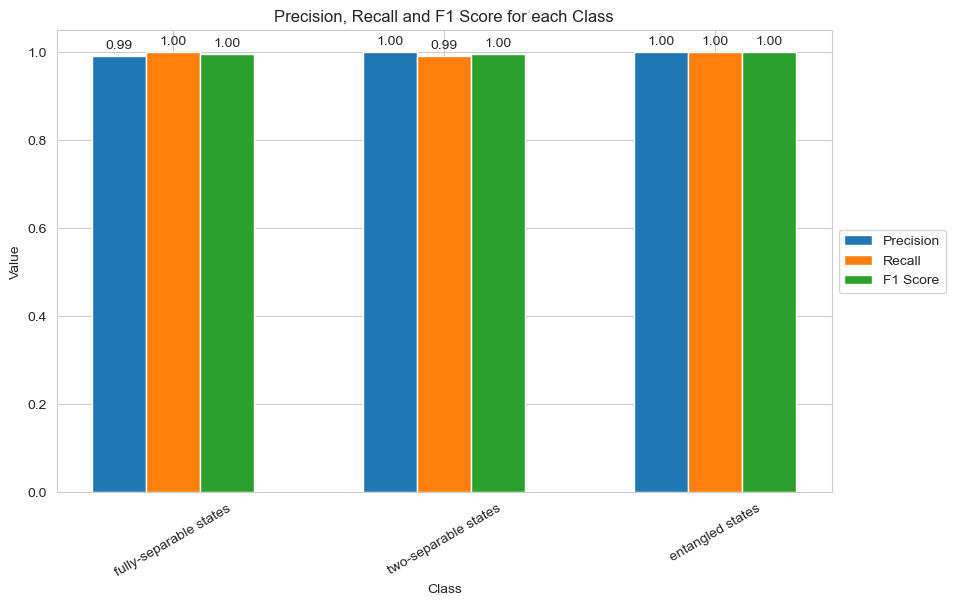

In [26]:
draw_prf1(precision_mlpd, recall_mlpd, f1_mlpd, label_dic)

对比图

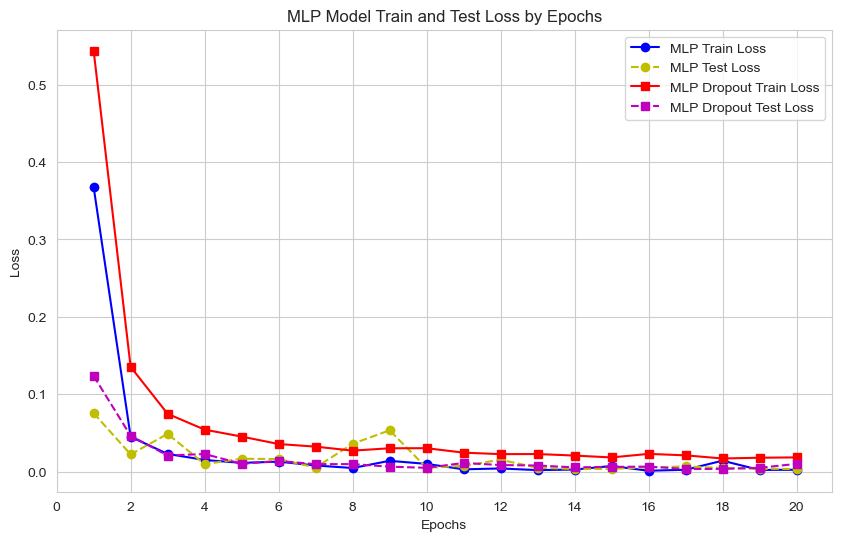

In [27]:
# 生成示例数据
epochs = range(1, 21)

# 绘制图像
plt.figure(figsize=(10, 6))

# MLP的Train loss 和 test loss
plt.plot(epochs, mlp_train_losses, 'bo-', label='MLP Train Loss')
plt.plot(epochs, mlp_test_losses, 'yo--', label='MLP Test Loss')

# MLP With Dropout的Train loss 和 test loss
plt.plot(epochs, mlpd_train_losses, 'rs-', label='MLP Dropout Train Loss')
plt.plot(epochs, mlpd_test_losses, 'ms--', label='MLP Dropout Test Loss')

plt.title('MLP Model Train and Test Loss by Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.xticks(range(0, len(epochs) + 1, 2))

plt.grid(True)
plt.legend()
plt.show()

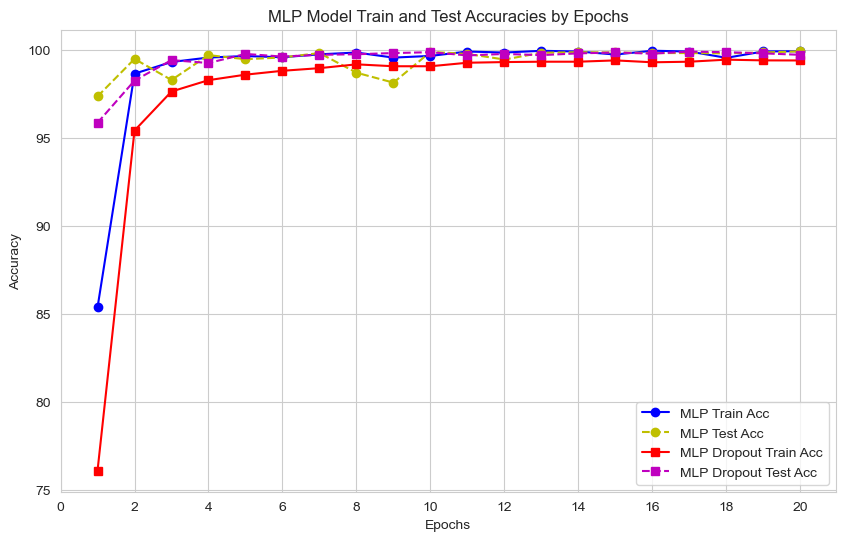

In [28]:
# 生成示例数据
epochs = range(1, 21)

# 绘制图像
plt.figure(figsize=(10, 6))

# mlp_train_accs 和 mlp_test_accs
plt.plot(epochs, mlp_train_accs, 'bo-', label='MLP Train Acc')
plt.plot(epochs, mlp_test_accs, 'yo--', label='MLP Test Acc')

# mlpd_train_accs 和 mlpd_test_accs
plt.plot(epochs, mlpd_train_accs, 'rs-', label='MLP Dropout Train Acc')
plt.plot(epochs, mlpd_test_accs, 'ms--', label='MLP Dropout Test Acc')

plt.title('MLP Model Train and Test Accuracies by Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(range(0, len(epochs) + 1, 2))

plt.grid(True)
plt.legend()
plt.show()

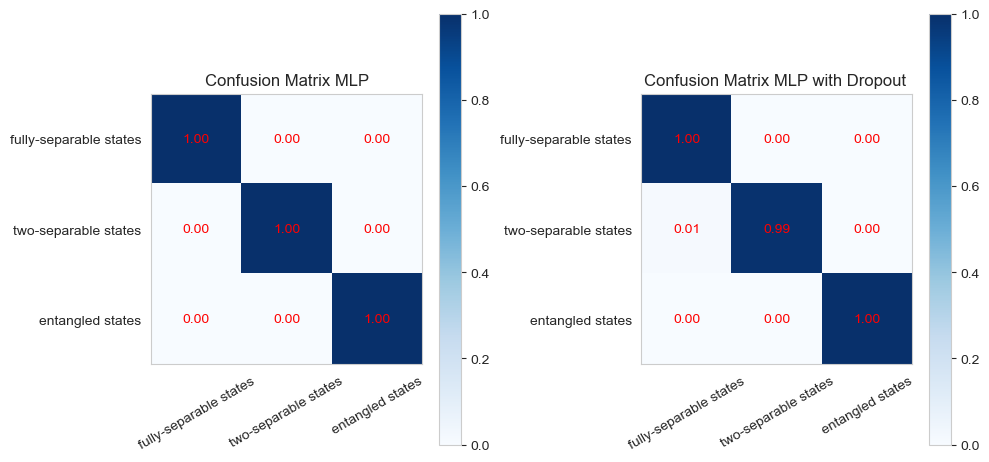

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# 示例混淆矩阵数据
conf_matrix1 = np.array(conf_matrix_percent_mlp)  # 第一个混淆矩阵数据
conf_matrix2 = np.array(conf_matrix_percent_mlpd)  # 第二个混淆矩阵数据

# 标签
labels = list(label_dic.values())  # 获取标签

# 创建图表
fig, axs = plt.subplots(1, 2, figsize=(12, 6))  # 创建两个子图

# 绘制第一个混淆矩阵
im1 = axs[0].imshow(conf_matrix1, cmap='Blues')  # 使用Blues色彩图显示第一个混淆矩阵

# 绘制第二个混淆矩阵
im2 = axs[1].imshow(conf_matrix2, cmap='Blues')  # 使用Blues色彩图显示第二个混淆矩阵

# 添加颜色条
fig.colorbar(im1, ax=axs[0])  # 在第一个子图旁边添加颜色条
fig.colorbar(im2, ax=axs[1])  # 在第二个子图旁边添加颜色条

# 在每个单元格中标注数据
for i in range(conf_matrix1.shape[0]):
    for j in range(conf_matrix1.shape[1]):
        axs[0].text(j, i, '{:.2f}'.format(conf_matrix1[i, j]), ha='center', va='center', color='red')  # 在第一个混淆矩阵上添加文本标签

for i in range(conf_matrix2.shape[0]):
    for j in range(conf_matrix2.shape[1]):
        axs[1].text(j, i, '{:.2f}'.format(conf_matrix2[i, j]), ha='center', va='center', color='red')  # 在第二个混淆矩阵上添加文本标签

# 设置图表标题和标签
axs[0].set_title('Confusion Matrix MLP')  # 第一个子图标题
axs[0].set_xticks(np.arange(len(labels)))  # 设置X轴刻度
axs[0].set_xticklabels(labels, rotation=30)  # 设置X轴标签并旋转30度
axs[0].set_yticks(np.arange(len(labels)))  # 设置Y轴刻度
axs[0].set_yticklabels(labels)  # 设置Y轴标签

axs[1].set_title('Confusion Matrix MLP with Dropout')  # 第二个子图标题
axs[1].set_xticks(np.arange(len(labels)))  # 设置X轴刻度
axs[1].set_xticklabels(labels, rotation=30)  # 设置X轴标签并旋转30度
axs[1].set_yticks(np.arange(len(labels)))  # 设置Y轴刻度
axs[1].set_yticklabels(labels)  # 设置Y轴标签

# 移除背景网格线
for ax in axs:
    ax.grid(False)  # 移除网格线
    
# 显示图表
plt.tight_layout()  # 调整子图布局以适应图表
plt.show()  # 显示图表


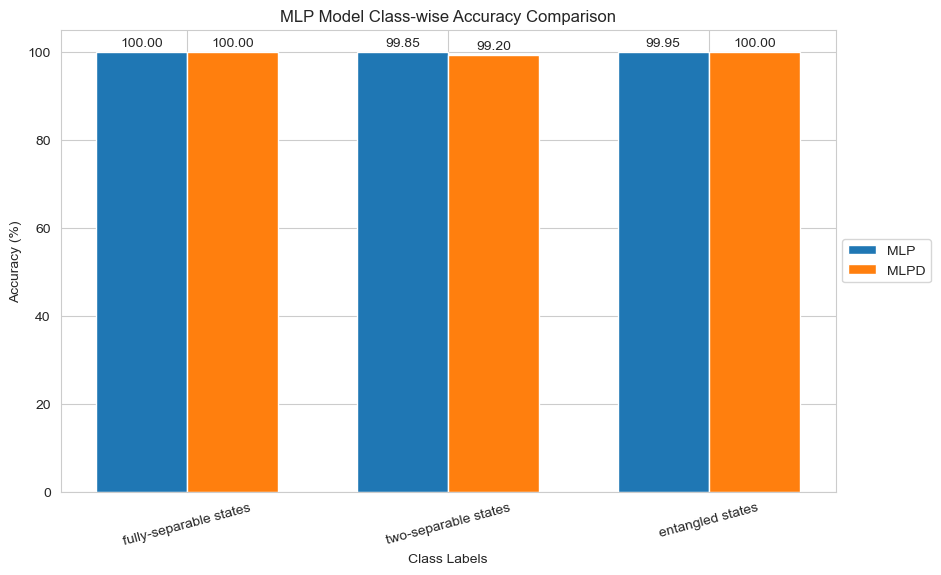

In [30]:
# 分类预测
x = np.arange(len(label_dic))
width = 0.35
label_dic = {0: 'fully-separable states', 1: 'two-separable states', 2: 'entangled states'}
fig, ax = plt.subplots(figsize=(10, 6))
bars_1 = ax.bar(x - width/2, class_accuracy_mlp, width, label='MLP')
bars_2 = ax.bar(x + width/2, class_accuracy_mlpd, width, label='MLPD')

# 添加标签、标题
ax.set_xlabel('Class Labels')
ax.set_ylabel('Accuracy (%)')
ax.set_title('MLP Model Class-wise Accuracy Comparison')
ax.set_xticks(x)
ax.set_xticklabels(label_dic.values(), rotation=15)


# 添加数值标签
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate('%.2f' % height,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 2),
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(bars_1)
autolabel(bars_2)
# 移动图例到右边
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

# 卷积神经网络模型

## LeNet-5神经网络

对于该数据集，可以设计一个简单的LeNet-5结构，适用于处理8x8的复数矩阵。以下是LeNet-5结构示例：

1. **卷积层1(Convolutional Layer 1)**：
   - 输入大小：2x8x8（8x8的复数矩阵，2表示实部和虚部）
   - 卷积核大小：5x5
   - 卷积核数量：6
   - 激活函数：ReLU
   - 输出大小：4x4x6

2. **池化层1(Pooling Layer 1)**：
   - 池化类型：最大池化（Max Pooling）
   - 池化窗口大小：2x2
   - 输出大小：6x2x2

3. **卷积层2(Convolutional Layer 2)**：
   - 输入大小：6x2x2
   - 卷积核大小：2x2
   - 卷积核数量：16
   - 激活函数：ReLU
   - 输出大小：16x1x1

4. **池化层2(Pooling Layer 2)**：
   - 池化类型：最大池化（Max Pooling）
   - 池化窗口大小：1x1
   - 输出大小：16x1x1

5. **全连接层1(Fully Connected Layer 1)**：
   - 输入大小：16x1x1
   - 输出大小：120
   - 激活函数：ReLU

6. **全连接层2(Fully Connected Layer 2)**：
   - 输入大小：120
   - 输出大小：84
   - 激活函数：ReLU

7. **输出层(Output Layer)**：
   - 输入大小：84
   - 输出大小：3（对应三个类别）


### 模型设计

In [31]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        # Define the layers
        self.conv1 = nn.Conv2d(in_channels=2, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)  # 最大池化层
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=2, stride=1, padding=0)
        self.pool2 = nn.MaxPool2d(kernel_size=1, stride=1)  # 最大池化层
        self.fc1 = nn.Linear(16 * 1 * 1, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 3)  # Three classes

    def forward(self, x):
        # Apply convolutional layers with ReLU activation and max pooling
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        # Flatten the output for fully connected layers
        # x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = x.view(-1, 16 * 1 * 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [32]:
# 实例化模型
model_le = LeNet5()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_le.parameters(), lr=0.001)

# 训练模型
num_epochs = 20
le_train_losses, le_test_losses, le_train_accs, le_test_accs = model_trainer(num_epochs, train_dataloader, test_dataloader, model_le, criterion, optimizer)

Start training
Epoch	Train Loss	Test Loss	Test Accuracy/%
1	 0.8163	 0.5364	 76.150
2	 0.3962	 0.3124	 87.350
3	 0.2642	 0.2281	 91.467
4	 0.2026	 0.1930	 92.350
5	 0.1718	 0.1786	 92.783
6	 0.1441	 0.1381	 94.750
7	 0.1193	 0.1001	 96.150
8	 0.0930	 0.0761	 97.483
9	 0.0634	 0.0601	 97.933
10	 0.0535	 0.0483	 98.283
11	 0.0403	 0.0404	 98.567
12	 0.0375	 0.0509	 98.200
13	 0.0322	 0.0295	 99.017
14	 0.0309	 0.0282	 99.100
15	 0.0235	 0.0235	 99.167
16	 0.0206	 0.0230	 99.250
17	 0.0201	 0.0197	 99.400
18	 0.0183	 0.0171	 99.500
19	 0.0168	 0.0196	 99.333
20	 0.0162	 0.0202	 99.433
Finished Training


In [33]:
# # 保存模型
# torch.save(model_le.state_dict(), 'models/model_le.pth', _use_new_zipfile_serialization=False)

验证模型效果

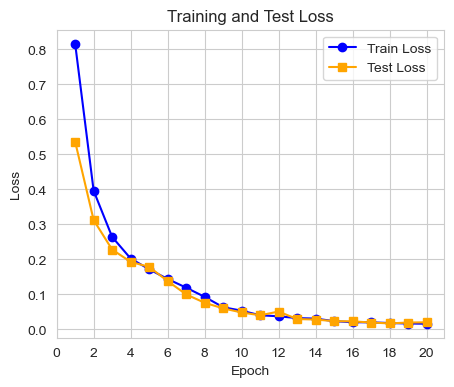

In [34]:
# Training and Test Loss
draw_loss(le_train_losses, le_test_losses)

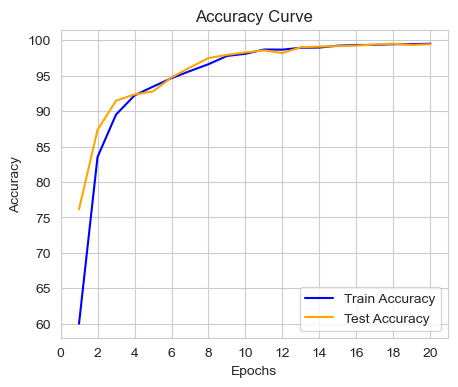

In [35]:
# Accuracy Curve
draw_acc(le_train_accs, le_test_accs)

In [36]:
# # 加载模型
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model_le = LeNet5()
# model_le.load_state_dict(torch.load('models/model_le.pth', map_location=device))
# model_le.to(device)

In [37]:
conf_matrix_percent_le, class_accuracy_le, precision_le, recall_le, f1_le = model_tester(test_dataloader, model_le)

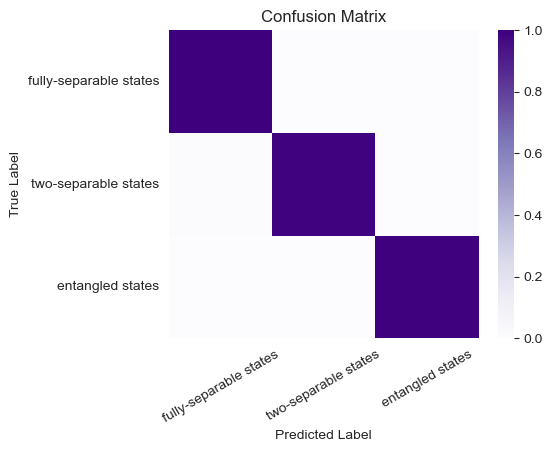

In [38]:
# Confusion Matrix
draw_confusion(conf_matrix_percent_le, label_dic)

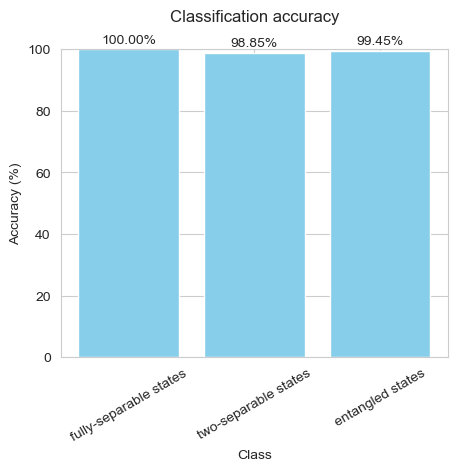

In [39]:
# Classification accuracy
draw_class_acc(class_accuracy_le, label_dic)

In [40]:
# 数据
precision = precision_le
recall = recall_le
f1 = f1_le
class_accuracy = class_accuracy_le

# 输出表头
print("Type\tPrecision/%\tRecall/%\tAccuracy/%\tF1")

# 输出每个类别的指标
for i, label in enumerate(label_dic.values()):
    print(f"{label}\t{precision[i] * 100:.2f}\t{recall[i] * 100:.2f}\t{class_accuracy[i]:.2f}\t{f1[i]:.2f}")

Type	Precision/%	Recall/%	Accuracy/%	F1
fully-separable states	98.96	100.00	100.00	0.99
two-separable states	99.45	98.85	98.85	0.99
entangled states	99.90	99.45	99.45	1.00


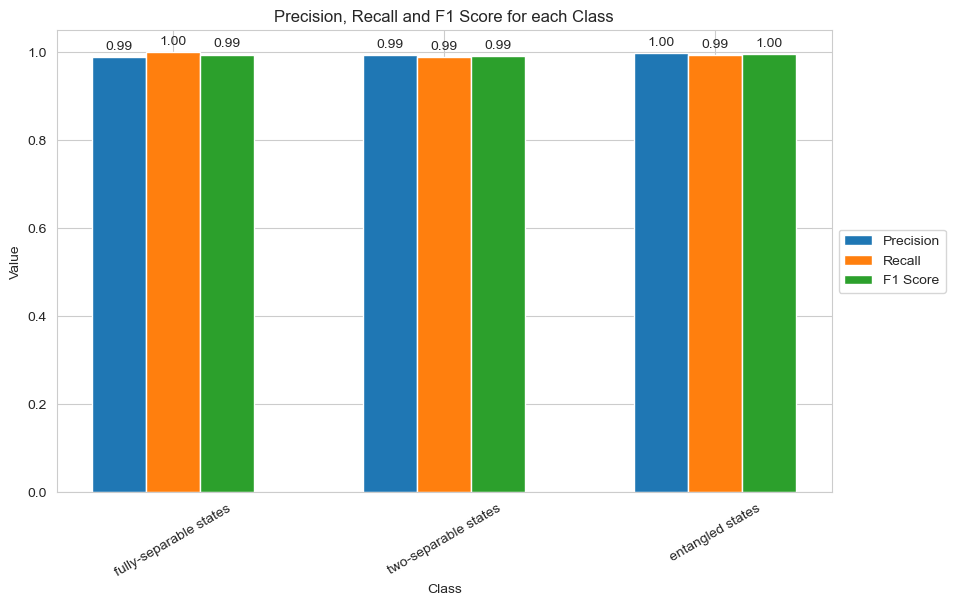

In [41]:
# Precision, Recall and F1 Score for each Class
draw_prf1(precision_le, recall_le, f1_le, label_dic)

### 采用Dropout防过拟合

In [42]:
class LeNet5WithDropout(nn.Module):
    def __init__(self):
        super(LeNet5WithDropout, self).__init__()
        # Define the layers
        self.conv1 = nn.Conv2d(in_channels=2, out_channels=6, kernel_size=5, stride=1, padding=0)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)  # 最大池化层
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=2, stride=1, padding=0)
        self.pool2 = nn.MaxPool2d(kernel_size=1, stride=1)  # 最大池化层
        self.fc1 = nn.Linear(16 * 1 * 1, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 3)  # Three classes
        self.dropout = nn.Dropout(p=0.5)  # 添加 Dropout 层，p 参数表示丢弃概率

    def forward(self, x):
        # Apply convolutional layers with ReLU activation and max pooling
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        # Flatten the output for fully connected layers
        # x = torch.flatten(x, 1)  # 将输入展平成一维张量
        x = x.view(-1, 16 * 1 * 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

In [43]:
# 实例化模型
model_led = LeNet5WithDropout()

# 定义损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_led.parameters(), lr=0.001)

# 训练模型
num_epochs = 20
led_train_losses, led_test_losses, led_train_accs, led_test_accs = model_trainer(num_epochs, train_dataloader, test_dataloader, model_led, criterion, optimizer)

Start training
Epoch	Train Loss	Test Loss	Test Accuracy/%
1	 0.8353	 0.4548	 80.900
2	 0.3985	 0.3153	 87.067
3	 0.2698	 0.2019	 92.633
4	 0.2094	 0.1849	 92.867
5	 0.1764	 0.1616	 93.583
6	 0.1572	 0.1152	 95.700
7	 0.1375	 0.0999	 96.517
8	 0.1230	 0.0948	 96.483
9	 0.1089	 0.0829	 96.917
10	 0.0997	 0.0731	 97.283
11	 0.0912	 0.0741	 97.267
12	 0.0796	 0.0540	 97.883
13	 0.0704	 0.0386	 98.467
14	 0.0537	 0.0372	 98.517
15	 0.0471	 0.0354	 98.700
16	 0.0402	 0.0645	 97.967
17	 0.0342	 0.0203	 99.267
18	 0.0324	 0.0198	 99.400
19	 0.0283	 0.0343	 99.017
20	 0.0249	 0.0201	 99.483
Finished Training


In [44]:
# # 保存模型
# torch.save(model_led.state_dict(), 'models/model_led.pth', _use_new_zipfile_serialization=False)

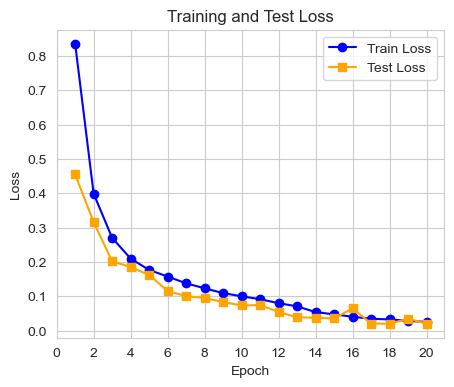

In [45]:
# Training and Test Loss
draw_loss(led_train_losses, led_test_losses)

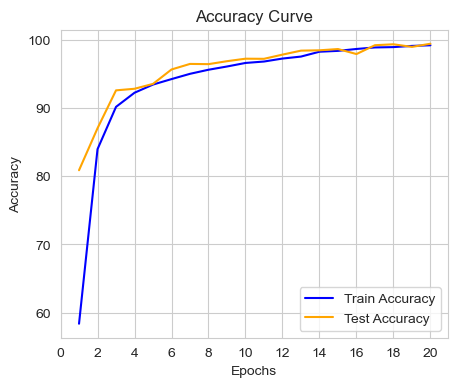

In [46]:
# Accuracy Curve
draw_acc(led_train_accs, led_test_accs)

In [47]:
# # 加载模型
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model_led = LeNet5WithDropout()
# model_led.load_state_dict(torch.load('models/model_led.pth', map_location=device))
# model_led.to(device)

In [48]:
conf_matrix_percent_led, class_accuracy_led, precision_led, recall_led, f1_led = model_tester(test_dataloader, model_led)

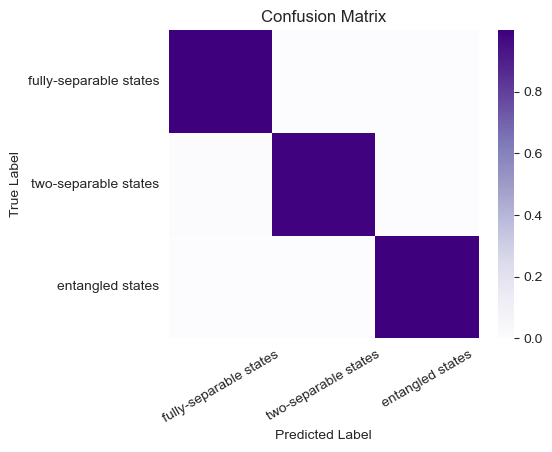

In [49]:
# Confusion Matrix
draw_confusion(conf_matrix_percent_led, label_dic)

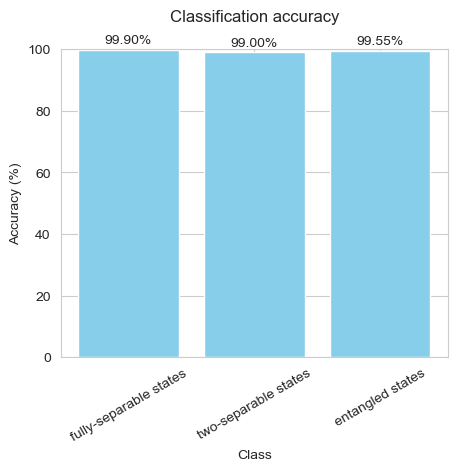

In [50]:
# Classification accuracy
draw_class_acc(class_accuracy_led, label_dic)

In [51]:
# 数据
precision = precision_led
recall = recall_led
f1 = f1_led
class_accuracy = class_accuracy_led

# 输出表头
print("Type\tPrecision/%\tRecall/%\tAccuracy/%\tF1")

# 输出每个类别的指标
for i, label in enumerate(label_dic.values()):
    print(f"{label}\t{precision[i] * 100:.2f}\t{recall[i] * 100:.2f}\t{class_accuracy[i]:.2f}\t{f1[i]:.2f}")

Type	Precision/%	Recall/%	Accuracy/%	F1
fully-separable states	98.96	99.90	99.90	0.99
two-separable states	99.50	99.00	99.00	0.99
entangled states	100.00	99.55	99.55	1.00


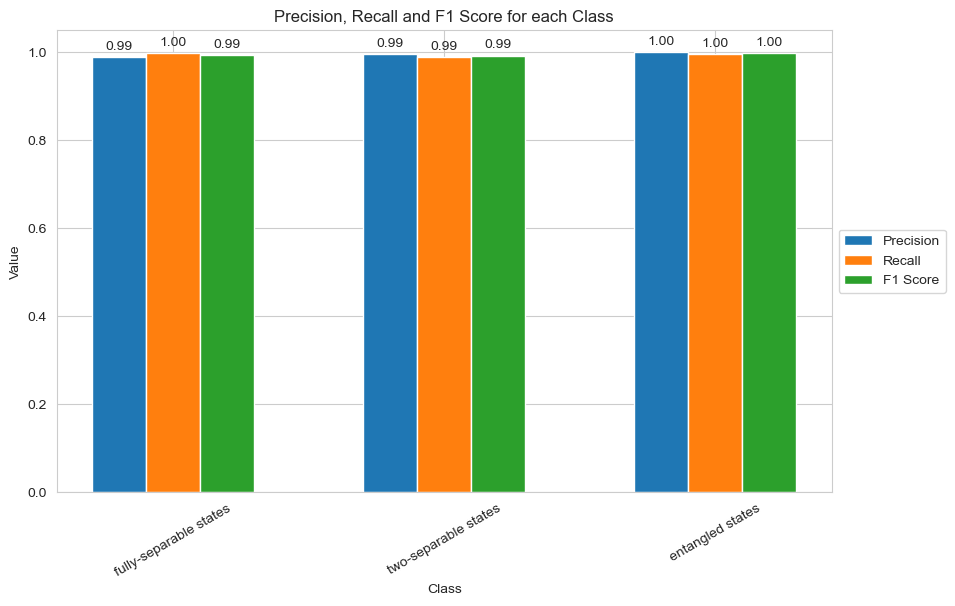

In [52]:
# Precision, Recall and F1 Score for each Class
draw_prf1(precision_led, recall_led, f1_led, label_dic)

对比图

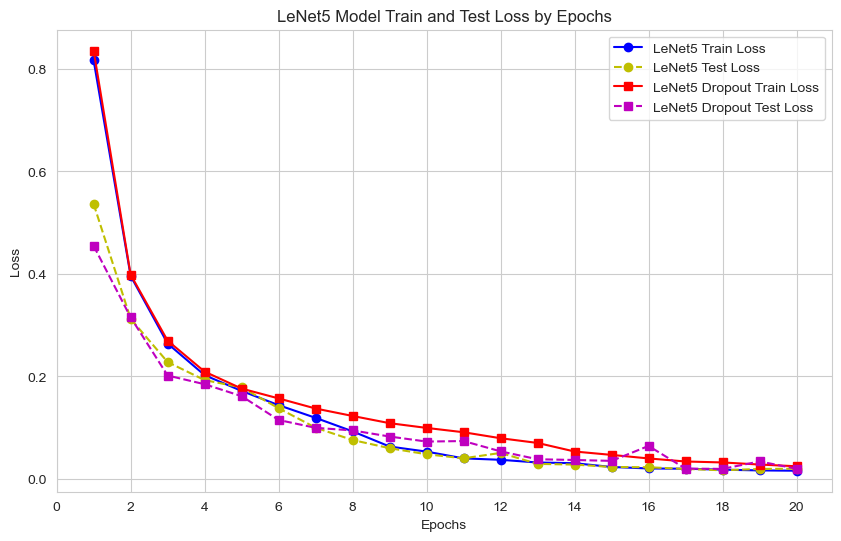

In [53]:
# 生成示例数据
epochs = range(1, 21)

# 绘制图像
plt.figure(figsize=(10, 6))

# LeNet5的Train loss 和 test loss
plt.plot(epochs, le_train_losses, 'bo-', label='LeNet5 Train Loss')
plt.plot(epochs, le_test_losses, 'yo--', label='LeNet5 Test Loss')

# LeNet5 With Dropout的Train loss 和 test loss
plt.plot(epochs, led_train_losses, 'rs-', label='LeNet5 Dropout Train Loss')
plt.plot(epochs, led_test_losses, 'ms--', label='LeNet5 Dropout Test Loss')

plt.title('LeNet5 Model Train and Test Loss by Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.xticks(range(0, len(epochs) + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

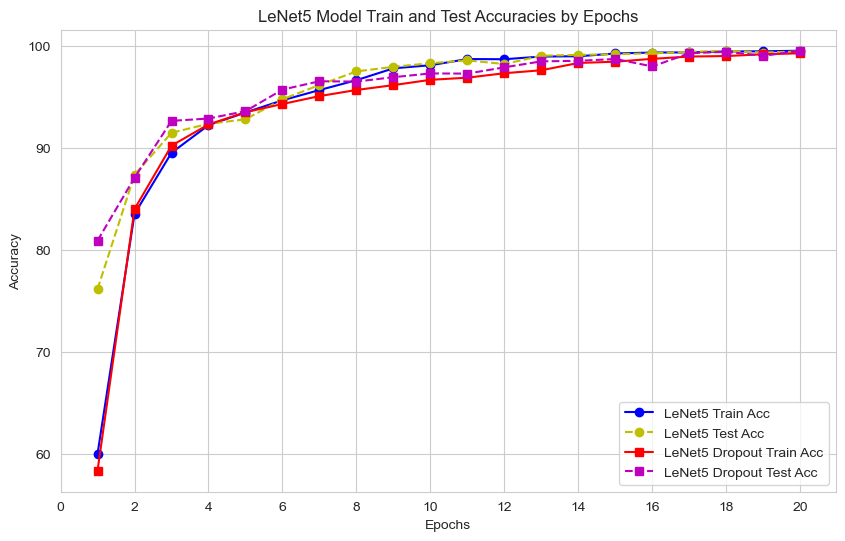

In [54]:
# 生成示例数据
epochs = range(1, 21)

# 绘制图像
plt.figure(figsize=(10, 6))

# le_train_accs 和 le_test_accs
plt.plot(epochs, le_train_accs, 'bo-', label='LeNet5 Train Acc')
plt.plot(epochs, le_test_accs, 'yo--', label='LeNet5 Test Acc')

# led_train_accs 和 led_test_accs
plt.plot(epochs, led_train_accs, 'rs-', label='LeNet5 Dropout Train Acc')
plt.plot(epochs, led_test_accs, 'ms--', label='LeNet5 Dropout Test Acc')

plt.title('LeNet5 Model Train and Test Accuracies by Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.xticks(range(0, len(epochs) + 1, 2))
plt.grid(True)
plt.legend()
plt.show()

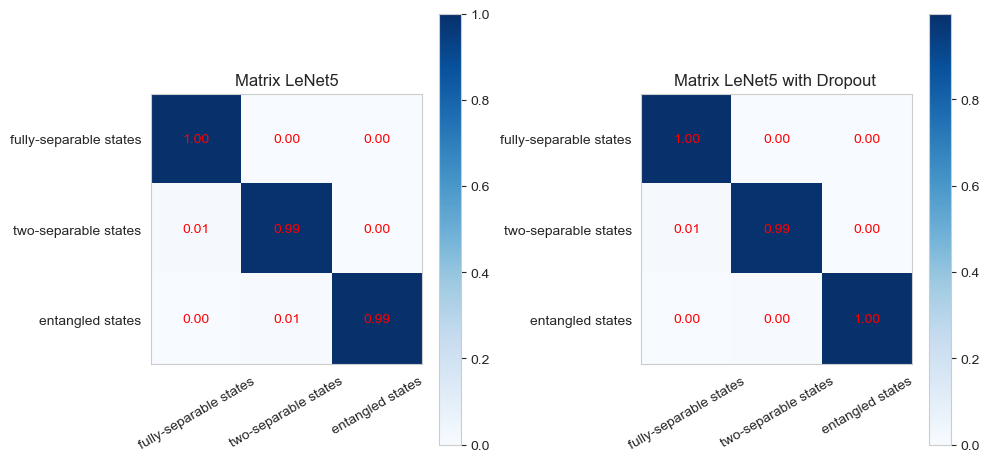

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# 示例混淆矩阵数据
conf_matrix1 = np.array(conf_matrix_percent_le)
conf_matrix2 = np.array(conf_matrix_percent_led)

# 标签
labels = label_dic.values()

# 创建图表
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

# 绘制第一个混淆矩阵
im1 = axs[0].imshow(conf_matrix1, cmap='Blues')

# 绘制第二个混淆矩阵
im2 = axs[1].imshow(conf_matrix2, cmap='Blues')

# 添加颜色条
fig.colorbar(im1, ax=axs[0])
fig.colorbar(im2, ax=axs[1])

# 在每个单元格中标注数据
for i in range(conf_matrix1.shape[0]):
    for j in range(conf_matrix1.shape[1]):
        axs[0].text(j, i, '{:.2f}'.format(conf_matrix1[i, j]), ha='center', va='center', color='red')

for i in range(conf_matrix2.shape[0]):
    for j in range(conf_matrix2.shape[1]):
        axs[1].text(j, i, '{:.2f}'.format(conf_matrix2[i, j]), ha='center', va='center', color='red')

# 设置图表标题和标签
axs[0].set_title('Matrix LeNet5')
axs[0].set_xticks(np.arange(len(labels)))
axs[0].set_xticklabels(labels, rotation=30)
axs[0].set_yticks(np.arange(len(labels)))
axs[0].set_yticklabels(labels)

axs[1].set_title('Matrix LeNet5 with Dropout ')
axs[1].set_xticks(np.arange(len(labels)))
axs[1].set_xticklabels(labels, rotation=30)
axs[1].set_yticks(np.arange(len(labels)))
axs[1].set_yticklabels(labels)

# 移除背景网格线
for ax in axs:
    ax.grid(False)
    
# 显示图表
plt.tight_layout()
plt.show()

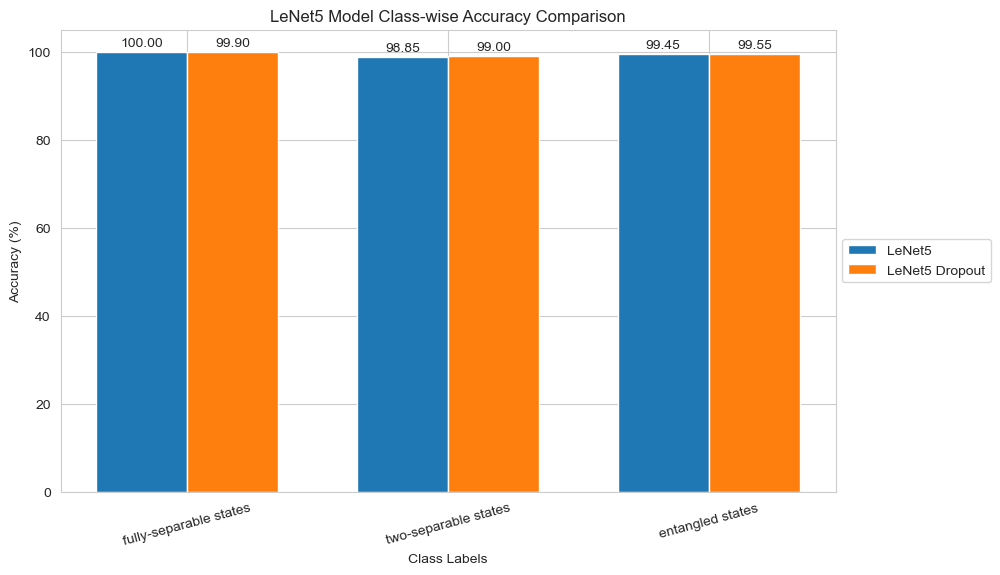

In [56]:
# 分类预测
x = np.arange(len(label_dic))
width = 0.35
label_dic = {0: 'fully-separable states', 1: 'two-separable states', 2: 'entangled states'}
fig, ax = plt.subplots(figsize=(10, 6))
bars_1 = ax.bar(x - width / 2, class_accuracy_le, width, label='LeNet5')
bars_2 = ax.bar(x + width / 2, class_accuracy_led, width, label='LeNet5 Dropout')

# 添加标签、标题
ax.set_xlabel('Class Labels')
ax.set_ylabel('Accuracy (%)')
ax.set_title('LeNet5 Model Class-wise Accuracy Comparison')
ax.set_xticks(x)
ax.set_xticklabels(label_dic.values(), rotation=15)


# 添加数值标签
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate('%.2f' % height,
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 2),
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(bars_1)
autolabel(bars_2)
# 移动图例到右边
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()